# The fix-first decision and its evidence: what does a call carry?

**Week 4, Thursday, SECTION 8, the last of five concept notebooks.** The college and its counts
are invented, the same as notebook 04, which found this cycle's loss at one step: offer
acceptance fell from 90 to 75 percent while the lowest step, shortlisting, held at 50. The fee of
Rs 1 to 1.5 lakh a year is an assumption, given with its range.

**Who needs the answer.** The college's dean, who has one admissions team for one fix before the
next cycle. The wrong fix leaves the lost students lost for another year.

**The questions on the way.**

1. Which of two problems goes first?
2. Whom does the loss hurt, since when?
3. How big is it, and what does it cost?
4. What answers the objection?

In [1]:
# Load the admissions counts (invented) and the fee assumption; print the rows split by home state.
import pandas as pd
import matplotlib.pyplot as plt

RESULTS = []
def check(name, ok):
    RESULTS.append(bool(ok)); print(("PASS  " if ok else "FAIL  ") + name)

adm = pd.read_csv("../data/C2_W04_D04_toy_admissions_STUDENT.csv")
FEE_LAKH = {"low": 1.0, "middle": 1.2, "high": 1.5}       # an assumption: a first-year fee, in Rs lakh
groups = adm.query("programme == 'main' and group in ['in-state', 'other states']")
print("Shortlisted and accepted by home state, three cycles (invented), in full:")
print(groups.to_string(index=False))

Shortlisted and accepted by home state, three cycles (invented), in full:
programme  cycle  fee_deadline_days         unit        group       stage  count
     main   2024                 21 applications     in-state shortlisted    240
     main   2024                 21 applications     in-state    accepted    221
     main   2024                 21 applications other states shortlisted    140
     main   2024                 21 applications other states    accepted    121
     main   2025                 21 applications     in-state shortlisted    250
     main   2025                 21 applications     in-state    accepted    230
     main   2025                 21 applications other states shortlisted    150
     main   2025                 21 applications other states    accepted    130
     main   2026                  7 applications     in-state shortlisted    250
     main   2026                  7 applications     in-state    accepted    225
     main   2026                  7

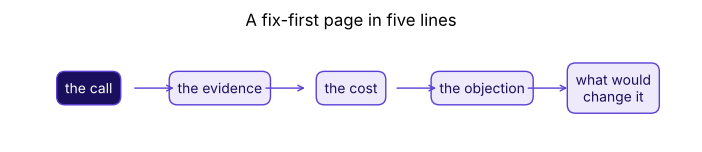

In [2]:
# The map: the chapter's steps in order; this notebook starts on the lit one and walks them all.
steps = ["the call", "the evidence", "the cost", "the objection", "what would\nchange it"]
fig, ax = plt.subplots(figsize=(8.8, 1.4))
for i, s in enumerate(steps):
    ax.text(i, 0, s, ha="center", va="center", fontsize=10, color="white" if i == 0 else "#1A0F5C",
            bbox=dict(boxstyle="round,pad=0.6", fc="#1A0F5C" if i == 0 else "#EEEAFB", ec="#5B3FD6"))
for i in range(1, len(steps)):
    ax.annotate("", xy=(i - 0.33, 0), xytext=(i - 0.67, 0), arrowprops=dict(arrowstyle="->", color="#5B3FD6"))
ax.set_xlim(-0.6, len(steps) - 0.4); ax.set_ylim(-0.7, 0.7); ax.axis("off")
ax.set_title("A fix-first page in five lines"); plt.show()

## Which of two problems goes first?

The dean has two problems: 200 of 1,000 applications skip the entrance test every cycle, and
offer acceptance fell from 90 to 75 percent this cycle. **Predict before you run.** Which goes
first?

- a) Both at once, split across the team
- b) The test's no-show, the bigger count at 200
- c) Offer acceptance
- d) Neither, until the next cycle confirms it

       sat the test  offers accepted
cycle                               
2024           80.0             90.0
2025           80.0             90.0
2026           80.0             75.0


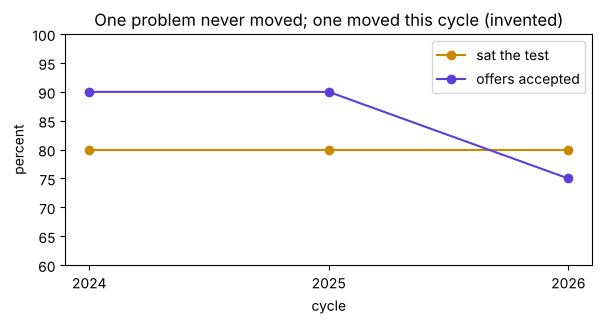

PASS  the share that sat the test is 80 percent in every cycle
PASS  acceptance read 90 for two cycles and 75 this cycle


In [3]:
# The two problems across three cycles: the share that sat the test, and the share of offers accepted.
main = adm.query("programme == 'main' and unit == 'applications' and group == 'all'")
c = main.pivot_table(index="cycle", columns="stage", values="count", aggfunc="sum")
two = pd.DataFrame({"sat the test": c["sat_test"] / c["applied"], "offers accepted": c["accepted"] / c["shortlisted"]})
print((100 * two).round(1))
ax = (100 * two).plot(marker="o", figsize=(6.8, 3.0), color=["#C98A00", "#5B3FD6"])
ax.set_xticks(two.index); ax.set_ylim(60, 100); ax.set_ylabel("percent")
ax.set_title("One problem never moved; one moved this cycle (invented)"); plt.show()
check("the share that sat the test is 80 percent in every cycle", set((100 * two["sat the test"]).round(1)) == {80.0})
check("acceptance read 90 for two cycles and 75 this cycle",
      list((100 * two["offers accepted"]).round(1)) == [90.0, 90.0, 75.0])

**What happened.** The answer is c. The test's no-show has read 20 percent for three cycles, so it
is how the test runs, and nothing changed there. A problem goes first when its step moved against
its own past; a bigger count that never moved waits.

## Whom does the loss hurt, since when?

The next cell splits acceptance by the student's home state, cycle by cycle, with the number of
days each cycle allowed to pay the fee after the offer.

group  in-state  other states
cycle                        
2024       92.1          86.4
2025       92.0          86.7
2026       90.0          50.0


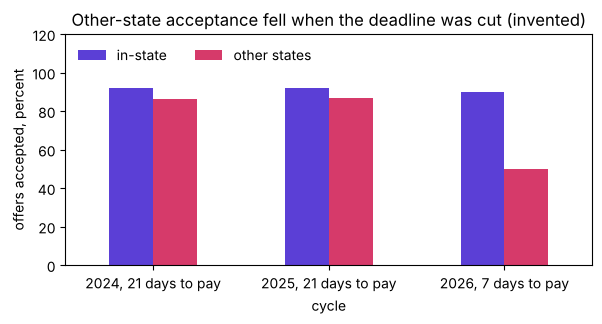

PASS  in-state acceptance held, 92 to 90
PASS  other-state acceptance fell from 87 to 50


In [4]:
# Acceptance by home state and cycle, with the days each cycle allowed to pay the fee.
g = groups.pivot_table(index=["cycle", "group"], columns="stage", values="count", aggfunc="sum")
rate = (g["accepted"] / g["shortlisted"]).unstack("group")
deadline = groups.groupby("cycle")["fee_deadline_days"].first()
print((100 * rate).round(1))
ax = (100 * rate).plot.bar(figsize=(6.8, 3.0), rot=0, color=["#5B3FD6", "#D63A6A"])
ax.set_xticklabels([f"{cy}, {d} days to pay" for cy, d in deadline.items()])
ax.set_ylabel("offers accepted, percent"); ax.set_ylim(0, 120); ax.legend(frameon=False, ncol=2, loc="upper left")
ax.set_title("Other-state acceptance fell when the deadline was cut (invented)"); plt.show()
check("in-state acceptance held, 92 to 90", (100 * rate["in-state"]).max() - (100 * rate["in-state"]).min() < 2.5)
check("other-state acceptance fell from 87 to 50", [round(100 * v) for v in rate["other states"].loc[[2025, 2026]]] == [87, 50])

## How big is it, and what does it cost?

By hand: at last cycle's rates, the 250 in-state students shortlisted this cycle would have
accepted 230, and the 150 from other states 130, so 360 in all; 300 accepted, so 60 fewer, 5
in-state and 55 from other states. Since 80 percent of those who accept join, 60 fewer
acceptances are 48 fewer students, and fees come from students who join. The next cell writes the
size as a function, checks it against the hand count, reaches 48 a second way from the joiners
counted directly, and prices it at the assumed fee.

group
in-state         5.0
other states    55.0
dtype: float64
PASS  the code's size equals the hand count: 5 in-state, 55 from other states
PASS  two routes to 48 fewer students agree: 60 x 0.8, and 288 less 240
{'low': 'Rs 48.0 lakh', 'middle': 'Rs 57.6 lakh', 'high': 'Rs 72.0 lakh'}


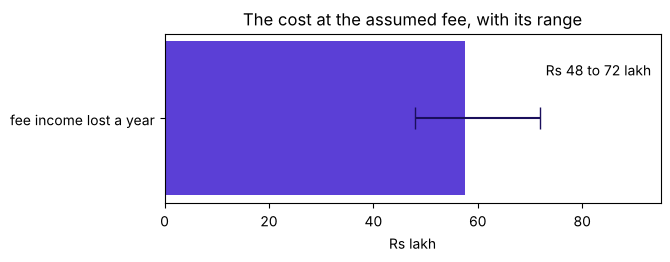

In [5]:
# The size as a function, the hand count checked, the second route, and the cost with its range.
def lost_at_old_rates(shortlisted_now, accepted_now, old_rate):
    """Acceptances lost: what last cycle's rate would have kept, less what this cycle kept."""
    return (shortlisted_now * old_rate - accepted_now).round()

by_hand = {"in-state": 5, "other states": 55}
now, last = g.loc[2026], g.loc[2025]
lost = lost_at_old_rates(now["shortlisted"], now["accepted"], last["accepted"] / last["shortlisted"])
print(lost)
check("the code's size equals the hand count: 5 in-state, 55 from other states", lost.to_dict() == by_hand)
joiners_lost = lost.sum() * 0.8
joined = c["joined"]
check("two routes to 48 fewer students agree: 60 x 0.8, and 288 less 240",
      joiners_lost == joined[2025] - joined[2026] == 48)
cost = {k: joiners_lost * v for k, v in FEE_LAKH.items()}
print({k: f"Rs {v:.1f} lakh" for k, v in cost.items()})
fig, ax = plt.subplots(figsize=(6.4, 2.2))
ax.barh(["fee income lost a year"], [cost["middle"]], color="#5B3FD6")
ax.errorbar([cost["middle"]], [0], xerr=[[cost["middle"] - cost["low"]], [cost["high"] - cost["middle"]]],
            color="#1A0F5C", capsize=8)
ax.text(cost["high"] + 1, 0.25, f"Rs {cost['low']:.0f} to {cost['high']:.0f} lakh", va="center")
ax.set_xlabel("Rs lakh"); ax.set_xlim(0, 95)
ax.set_title("The cost at the assumed fee, with its range"); plt.show()

**The plausible wrong answer.** "Fix the test first: 200 applications never sit it." The decision
it would mislead: the one admissions team spends a cycle on a step that has read 80 percent for
three cycles, while 55 students from other states a cycle keep turning the offer down. **Why it is
wrong.** The step never moved, so fixing it wins back nothing lost this cycle.

## What answers the objection?

The admissions office says: "Our offers go out within two days of the shortlist, every one, so
acceptance is not our problem." **What is true.** The offers held: every shortlisted student got
an offer on time in both cycles. **What answers it.** The fall sits after the offer, in the days
allowed to pay, for one group, from the cycle the deadline shrank from 21 to 7 days. Concede the
true part, then bring the split.

## Your turn: was other-state acceptance falling before the deadline changed?

The page's last line names the fact that would change the call: other-state acceptance already
falling before the deadline was cut. **Your turn.** In the empty cell, print other-state
acceptance for 2024 and 2025 from `rate`, and say whether the fall began before 2026.

```python
rate["other states"]
```

**Check your cell against this one.** It prints the two cycles before the cut, then the five-line
page written from the numbers, then counts every check this notebook has run.

In [6]:
# The two cycles before the cut; the five-line page printed from the numbers; every check counted.
before = (100 * rate["other states"].loc[[2024, 2025]]).round(1)
print(before)
check("other-state acceptance read 86.4 and 86.7 before the cut, so it was not already falling",
      list(before) == [86.4, 86.7])
acc = 100 * two["offers accepted"]
page = [
    "The call. Give other-state offers a longer fee deadline first; the test's no-show waits, since it never moved.",
    f"The evidence. Offer acceptance fell from {acc[2025]:.0f} to {acc[2026]:.0f} percent; for other-state students "
    f"from {100 * rate['other states'][2025]:.0f} to {100 * rate['other states'][2026]:.0f}, while in-state held at "
    f"{100 * rate['in-state'][2025]:.0f} to {100 * rate['in-state'][2026]:.0f} on the same step, from the cycle the "
    f"deadline went from {deadline[2025]} to {deadline[2026]} days.",
    f"The cost. {lost.sum():.0f} fewer acceptances, {joiners_lost:.0f} fewer students, Rs {cost['low']:.0f} to "
    f"{cost['high']:.0f} lakh of first-year fees at an assumed Rs 1 to 1.5 lakh.",
    "The objection. Offers did go out in two days, which is true; the fall came after the offer, for one group, after one change.",
    f"What would change it. Other-state acceptance falling before the deadline changed; it read {before.iloc[0]:.0f} "
    f"and {before.iloc[1]:.0f} in the two cycles before.",
]
print("\n".join(f"{i}. {line}" for i, line in enumerate(page, 1)))
print(f"\n{sum(RESULTS)} of {len(RESULTS)} checks pass")

cycle
2024    86.4
2025    86.7
Name: other states, dtype: float64
PASS  other-state acceptance read 86.4 and 86.7 before the cut, so it was not already falling
1. The call. Give other-state offers a longer fee deadline first; the test's no-show waits, since it never moved.
2. The evidence. Offer acceptance fell from 90 to 75 percent; for other-state students from 87 to 50, while in-state held at 92 to 90 on the same step, from the cycle the deadline went from 21 to 7 days.
3. The cost. 60 fewer acceptances, 48 fewer students, Rs 48 to 72 lakh of first-year fees at an assumed Rs 1 to 1.5 lakh.
4. The objection. Offers did go out in two days, which is true; the fall came after the offer, for one group, after one change.
5. What would change it. Other-state acceptance falling before the deadline changed; it read 86 and 87 in the two cycles before.

7 of 7 checks pass


## What does a fix-first call carry to survive the meeting?

1. **The call**, in one sentence: what gets fixed first, and what waits.
2. **The evidence**: the step against its own past, the group it hurts and the date it started,
   with a comparator on the same step that held.
3. **The cost**, counted in the unit the business is paid in, with every assumption named and
   ranged.
4. **The objection**, with its true part conceded before the split that answers it.
5. **What would change it**: the one fact that would reverse the order.

**In the interview.** [D] "What evidence do you bring when the owning team says its step is
fine?" The step against its own past, the group and the date, a comparator that held, the size
with its range, and the true part of their claim conceded.

**What comes next.** SECTION 9 writes the same five lines for Zomato Gold's two problems, from
notebooks 06 and 07, and the lab's Kalpa set asks for them on Kalpa.